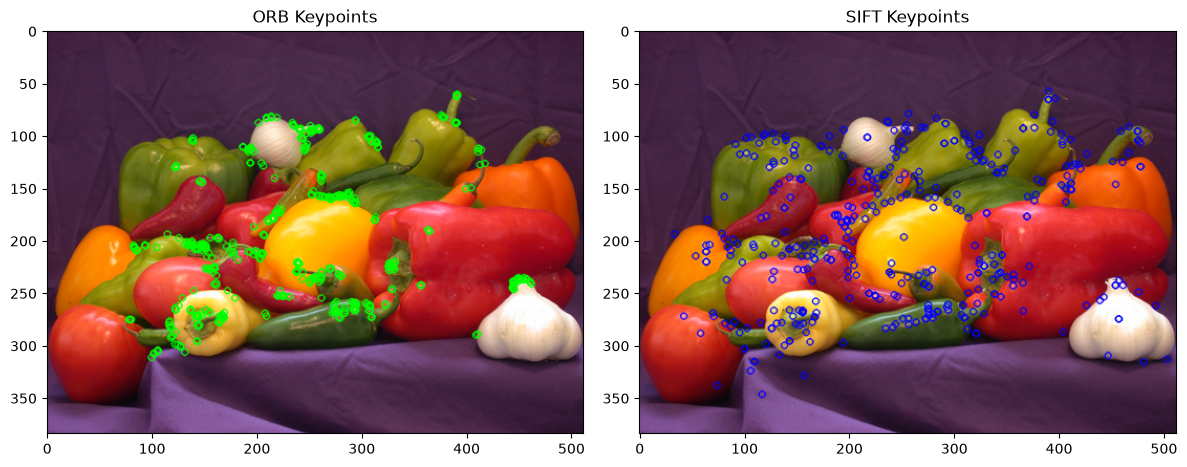

In [2]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('peppers.png')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

orb = cv2.ORB_create()
orb_keypoints, orb_descriptors = orb.detectAndCompute(gray, None)

img_orb = cv2.drawKeypoints(img, orb_keypoints, None, color=(0, 255, 0))

sift = cv2.SIFT_create()
sift_keypoints, sift_descriptors = sift.detectAndCompute(gray, None)

img_sift = cv2.drawKeypoints(img, sift_keypoints, None, color=(255, 0, 0))

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1), plt.imshow(cv2.cvtColor(img_orb, cv2.COLOR_BGR2RGB)), plt.title('ORB Keypoints')
plt.subplot(1, 2, 2), plt.imshow(cv2.cvtColor(img_sift, cv2.COLOR_BGR2RGB)), plt.title('SIFT Keypoints')
plt.tight_layout()
plt.show()


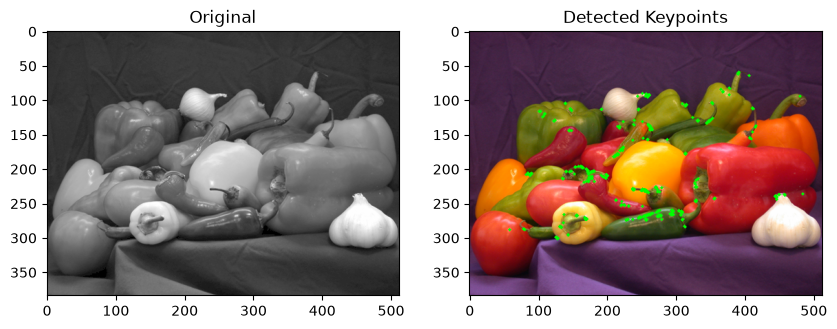

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import cv2  


img = cv2.imread('peppers.png', cv2.IMREAD_GRAYSCALE)
h, w = img.shape

output_img = cv2.imread('peppers.png') 

threshold = 40 

for i in range(3, h - 3):
    for j in range(3, w - 3):
        center_intensity = int(img[i, j])
        
        circle_pixels = [
            int(img[i-3, j]), # Top
            int(img[i+3, j]), # Bottom
            int(img[i, j-3]), # Left
            int(img[i, j+3])  # Right
        ]
        
        brighter = sum(1 for p in circle_pixels if p - center_intensity > threshold)
        darker = sum(1 for p in circle_pixels if center_intensity - p > threshold)

        if brighter >= 3 or darker >= 3:
            cv2.circle(output_img, (j, i), 2, (0, 255, 0), -1)

# 3. Display the results
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(img, cmap='gray'), plt.title('Original')
plt.subplot(1, 2, 2), plt.imshow(cv2.cvtColor(output_img, cv2.COLOR_BGR2RGB)), plt.title('Detected Keypoints')
plt.show()
